# Day 3 · Sequential pattern mining — the day the NMF components become motifs

**Today's goal:** produce a **named motif catalog** straight from the letrozole-cohort event
streams, with support counts, grouped by the 8 NMF components Day 1 found (k=8). No embeddings, no GPU, no licence. If you only have one day, spend it here.

### Summary

Sequential pattern mining searches for ordered subsequences that recur across patients. The
output is a list like `letrozole -> pregnancy_test -> clomiphene`, each with a count. That is exactly the
artifact Zack has been asking for: discrete, nameable, countable, writable as a rule. It is
also the technique most ML curricula omit entirely, which is why it keeps getting skipped in
favour of much heavier machinery.

### Technique chosen per subtopic

| Subtopic | We use | Mentioned only |
|---|---|---|
| Itemset mining | *mentioned* | Apriori, FP-Growth, ECLAT |
| Sequence mining | **PrefixSpan**, implemented in ~25 lines | GSP, SPADE, CM-SPAM |
| Redundancy control | **closed patterns** | maximal patterns, top-k, MDL compression |
| Interest measure | **discriminative lift** | confidence, leverage, conviction |
| Interval logic | **signed gaps** | Allen's 13 relations, KarmaLego |
| Trajectory view | **transition graph** via networkx | process mining, `pm4py` |

We implement PrefixSpan by hand rather than installing SPMF. It is short, and understanding
the projection step is what lets you reason about why the output explodes.

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)
import ethos_omop as eo

OUT_DIR = "../../inputs/letrozole_cohort/"   # matches Day 1's extract_cohort() output dir
DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']

if not os.path.isdir(OUT_DIR):
    raise FileNotFoundError(
        f"{OUT_DIR}/ not found. Run Day 1's eo.extract_cohort(...) (or "
        f"eo.extract_omop(...) with OUT_DIR='omop_extract') first, or "
        f"python make_demo_extract.py for a synthetic stand-in.")

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
events   = eo.tag_events(eo.load_events(OUT_DIR, domains=DOMAINS), codesets)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

print(f"events {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events (2421087, 11)   patients 5238
codeset coverage: 6.3% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,tag,in_codeset
0,1949,38004338,2019-07-01,Visit,NUCC,333600000X,Pharmacy,Visit,NUCC/333600000X,pharmacy__visit__38004338,False
1,1949,38004338,2019-07-01,Visit,NUCC,333600000X,Pharmacy,Visit,NUCC/333600000X,pharmacy__visit__38004338,False
2,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
3,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
4,1949,38004338,2019-09-25,Visit,NUCC,333600000X,Pharmacy,Visit,NUCC/333600000X,pharmacy__visit__38004338,False
5,1949,38004338,2019-09-25,Visit,NUCC,333600000X,Pharmacy,Visit,NUCC/333600000X,pharmacy__visit__38004338,False


In [2]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
pharmacy__visit__38004338 -> 7_ethinyl_estradiol___branded_pack__19129357 -> pharmacy__visit__38004338 -> nitrofurantoin_macro__clinical_drug__46234346 -> pharmacy__visit__38004338 -> 7_ethinyl_estradiol___branded_pack__19129357 -> pharmacy__visit__38004338 -> 7_ethinyl_estradiol___branded_pack__19129357 -> pharmacy__visit__38004338 -> hydrocortisone_0025___clinical_drug__19002273 -> pharmacy__visit__38004338 -> 7_ethinyl_estradiol___branded_pack__19129357

median sequence length: 261


### The two preprocessing decisions, restated

Both live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.

## 1 · PrefixSpan, implemented

In [3]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in set(seq):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

In [4]:
import hashlib, json

PAT_CACHE = "patterns_letrozole.json"   # PrefixSpan output + closed set; delete to force a re-mine
MIN_SUP   = int(0.04 * len(db))                     # 4% of patients

def db_key(db, min_sup, max_len):
    """Fingerprint of everything the mined patterns depend on."""
    h = hashlib.sha1()
    for s in db:
        h.update("\x1e".join(s).encode()); h.update(b"\x1f")
    return f"{len(db)}:{min_sup}:{max_len}:{h.hexdigest()}"

KEY    = db_key(db, MIN_SUP, 4)
cached = None
if os.path.exists(PAT_CACHE):
    with open(PAT_CACHE) as f:
        cached = json.load(f)
    if cached.get('key') != KEY:                    # stale: different sequences / support / max_len
        cached = None

if cached is not None:
    pats = pd.DataFrame({'pattern':     [tuple(p) for p, _, _ in cached['pats']],
                         'support':     [s for _, s, _ in cached['pats']],
                         'support_pct': [pc for _, _, pc in cached['pats']]})
    print(f"patterns loaded from {PAT_CACHE}")
else:
    pats = prefixspan(db, MIN_SUP, max_len=4)
    pats = (pats[pats.pattern.map(len) >= 3]
            .sort_values('support', ascending=False).reset_index(drop=True))
print(f"{len(pats)} patterns of length >= 3 at support {MIN_SUP}\n")
display(pats.head(12))


2452720 patterns of length >= 3 at support 209



,pattern,support,support_pct
0,"(pharmacy__visit__38004338, pharmacy__visit__3...",5223,99.7
1,"(pharmacy__visit__38004338, pharmacy__visit__3...",5206,99.4
2,"(pharmacy__visit__38004338, letrozole, pharmac...",5147,98.3
3,"(pharmacy__visit__38004338, pharmacy__visit__3...",5140,98.1
4,"(pharmacy__visit__38004338, pharmacy__visit__3...",5050,96.4
5,"(letrozole, pharmacy__visit__38004338, pharmac...",5045,96.3
6,"(pharmacy__visit__38004338, letrozole, pharmac...",5045,96.3
7,"(pharmacy__visit__38004338, pharmacy__visit__3...",5040,96.2
8,"(letrozole, pharmacy__visit__38004338, pharmac...",4942,94.3
9,"(pharmacy__visit__38004338, pharmacy__visit__3...",3869,73.9


## 2 · The redundancy problem, and closed patterns

Most of those are junk — prefixes of each other, or ambient primary care. **Closed** patterns
drop any pattern with a longer extension at the *same* support, removing prefix chains
without losing information.

Budget real time for this on the full vocabulary. Pattern pruning is the majority of the
work.

In [6]:
rows = list(pats.itertuples(index=False))
if cached is not None and 'closed' in cached:
    closed_idx = cached['closed']
else:
    # A pattern p is non-closed iff some super-pattern has the same support. Support never
    # increases when a pattern grows, so every pattern between p and that super-pattern has the
    # same support too -- in particular one with exactly one extra item. So it is enough to take
    # each pattern's one-item deletions and flag those with equal support: O(N * L), no pairwise scan.
    support   = {p.pattern: p.support for p in rows}
    dominated = set()
    for q in rows:
        for i in range(len(q.pattern)):
            sub = q.pattern[:i] + q.pattern[i + 1:]
            if support.get(sub) == q.support:
                dominated.add(sub)
    closed_idx = [i for i, p in enumerate(rows) if p.pattern not in dominated]
    with open(PAT_CACHE, 'w') as f:                 # persist for the next session
        json.dump({'key': KEY,
                   'pats': [[list(r.pattern), int(r.support), float(r.support_pct)] for r in rows],
                   'closed': closed_idx}, f)
    print(f"patterns + closed set saved to {PAT_CACHE}")
closed = [rows[i] for i in closed_idx]
print(f"{len(rows)} patterns -> {len(closed)} closed")


patterns + closed set saved to patterns_letrozole.json
2452720 patterns -> 2392883 closed


## 3 · Discriminative mining — where the motifs appear

Raw support finds whatever is common, which is mostly ambient care. What you want is
patterns common **inside** a group and rare **outside** it. That ratio is the interest
measure that produces usable motifs.

Group membership can come from anywhere — a weak label, a cluster, a codeset. Here the groups
are the **8 NMF components from Day 1** (k=8: largest k solid on 5/5 splits, k=9 is the cliff;
all 8 stable, cosine 0.988-0.997, ARI 0.899). What Day 1 concluded:

- **Fertility, four bundles (37.5%):** treatment c2, carrier screening c4, prenatal labs c7,
  pregnancy outcome c0.
- **Oncology, one bundle: c5 (7.2%).** Its top-10 codes look procedural, but `breast_cancer`,
  chemotherapy and mastectomy load there at low ranks. n=379 is a lower bound.
- **Background, c1, c3, c6 (55%):** no letrozole signal; one code in the bundle doesn't give the reason.

Day 1 told us *which codes co-occur*; Day 3 tells us *in what order*, per component. The draft
triage (needs underwriter review) is printed next to each component below.


In [7]:
from scipy import sparse as sp
from sklearn.decomposition import NMF

# Rebuild Day 1's k=8 NMF exactly (same prevalence floor, same anchor drop, same NMF_KW; nndsvd
# init is deterministic), so component numbers match the Day 1 loadings tables.
# The fit is cached next to the notebook (Day 1 writes the same file); delete CACHE to force a refit. The cache is used only
# if its code columns and patient ids match this extract.
n_pat      = events.person_id.nunique()
N_TRAIN    = min(20_000, int(0.6 * n_pat))
MIN_PAT    = int(np.ceil(5 * n_pat / N_TRAIN))
prev_pat   = events.groupby('tag').person_id.nunique()
KEEP_TAGS  = prev_pat.index[prev_pat >= MIN_PAT]
nmf_cols   = KEEP_TAGS.drop('letrozole')                 # cohort anchor, 100% prevalence
CACHE      = "nmf_k8_letrozole.npz"       # same file Day 1 writes

z = np.load(CACHE) if os.path.exists(CACHE) else None
if z is not None and (set(z['cols']) != set(nmf_cols)
                      or set(z['pids']) != set(events.person_id.unique())):
    z = None                                             # stale: different extract / floor

if z is not None:
    H   = pd.DataFrame(z['H'], columns=z['cols'])
    lab = pd.Series(z['labels'], index=z['pids'])
    print(f"NMF k=8 loaded from {CACHE}")
else:
    Xb   = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
    Xs   = sp.csr_matrix(Xb[nmf_cols].to_numpy()).astype(float)
    nmf  = NMF(n_components=8, init='nndsvd', random_state=0, max_iter=2000, tol=1e-4).fit(Xs)
    H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab  = pd.Series(nmf.transform(Xs).argmax(1), index=Xb.index)
    np.savez(CACHE, H=H.to_numpy(), cols=np.array(H.columns, dtype=str), pids=lab.index.to_numpy(),
             labels=lab.to_numpy())
    print(f"NMF k=8 fitted, cached to {CACHE}")

comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# Day 1 conclusions: names, which side of the indication each bundle sits on, draft triage.
# DRAFT triage -- needs underwriter review. The assert fails loudly if numbering drifted from Day 1.
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
COMP = {0: ('pregnancy_outcome',   'pregnancy outcome',                         FERT, EXPLAINED),
        1: ('pharmacy__visit',     'acute-care pharmacy (also hosts oral endocrine drugs)', BG, UNCLEAR),
        2: ('gonadotropin_drug',   'fertility treatment (high-intensity: ART, gonadotropins)', FERT, EXPLAINED),
        3: ('lipid_panel',         'preventive labs (+ milder PCOS / ovarian-reserve workup)', BG, UNCLEAR),
        4: ('cftr',                'preconception carrier screening',           FERT, EXPLAINED),
        5: ('ondansetron',         'oncology (breast_cancer, chemo, mastectomy load at low ranks)', ONCO, MANUAL),
        6: ('therapeutic_procedur','therapeutic / manual procedures',           BG, UNCLEAR),
        7: ('abo_typing',          'prenatal labs (ABO / Rh)',                  FERT, EXPLAINED)}
for c, (prefix, *_) in COMP.items():
    top = H.iloc[c].idxmax()
    assert top.startswith(prefix), (f"component {c} top code is {top!r}, expected {prefix!r}* -- "
                                    f"numbering differs from Day 1; re-read its top codes and fix COMP")

print(f"{'comp':>4} {'n':>5} {'%':>5}  {'group':<10} name")
for c, (_, name, grp, _) in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>5} {n / len(comp) * 100:5.1f}  {grp:<10} {name}")
print("\nc5 n is a LOWER BOUND: oral endocrine drugs partly load on c1, so some oncology patients argmax there.")


NMF k=8 fitted, cached to nmf_k8_letrozole.npz
comp     n     %  group      name
   0   614  11.7  fertility  pregnancy outcome
   1  1879  35.9  background acute-care pharmacy (also hosts oral endocrine drugs)
   2   561  10.7  fertility  fertility treatment (high-intensity: ART, gonadotropins)
   3   634  12.1  background preventive labs (+ milder PCOS / ovarian-reserve workup)
   4   279   5.3  fertility  preconception carrier screening
   5   379   7.2  oncology   oncology (breast_cancer, chemo, mastectomy load at low ranks)
   6   377   7.2  background therapeutic / manual procedures
   7   515   9.8  fertility  prenatal labs (ABO / Rh)

c5 n is a LOWER BOUND: oral endocrine drugs partly load on c1, so some oncology patients argmax there.


In [8]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values('lift', ascending=False).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values('support', ascending=False).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.10, max_cand=60, n_out=1500, seed=0, n_jobs=None):
    """All components in parallel (they are independent), like Day 1's k-sweep."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    jobs = []
    for c in COMP:
        idx_in  = np.flatnonzero(comp == c)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(COMP, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 5% components entirely
motifs = component_motifs()
for c, (_, name, grp, triage) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{grp}]: {name}  (n={(comp == c).sum()})")
    print(f"      draft triage: {triage}")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done 3 out of 8 | elapsed:  1.2min remaining:  2.0min
[Parallel(n_jobs=8)]: Done 5 out of 8 | elapsed:  2.7min remaining:  1.6min



===== component 0 [fertility]: pregnancy outcome  (n=614)
      draft triage: routine (letrozole explained by fertility)


[Parallel(n_jobs=8)]: Done 8 out of 8 | elapsed:  9.0min finished


,pattern,sup_in,sup_out,lift
0,letrozole -> pharmacy__visit__38004338 -> phar...,0.866,0.196,4.3
1,letrozole -> pregnancy_outcome -> pharmacy__vi...,0.860,0.191,4.3
2,letrozole -> pharmacy__visit__38004338 -> preg...,0.847,0.190,4.3
3,pharmacy__visit__38004338 -> letrozole -> preg...,0.860,0.191,4.3



===== component 1 [background]: acute-care pharmacy (also hosts oral endocrine drugs)  (n=1879)
      draft triage: routine, indication unclear (use other evidence)


...

,pattern,sup_in,sup_out,lift
0,complete_blood_count__procedure__4319466 -> co...,0.807,0.253,3.1
1,pharmacy__visit__38004338 -> pharmacy__visit__...,0.847,0.299,2.8
2,comprehensive_metabo__procedure__3661905 -> co...,0.852,0.308,2.7
3,pharmacy__visit__38004338 -> comprehensive_met...,0.850,0.307,2.7



===== component 6 [background]: therapeutic / manual procedures  (n=377)
      draft triage: routine, indication unclear (use other evidence)


,pattern,sup_in,sup_out,lift
0,manual_therapy_techn__cpt4__2314290 -> pharmac...,0.727,0.130,5.3
1,pharmacy__visit__38004338 -> pharmacy__visit__...,0.732,0.131,5.3
2,pharmacy__visit__38004338 -> manual_therapy_te...,0.735,0.130,5.3
3,pharmacy__visit__38004338 -> therapeutic_proce...,0.740,0.133,5.3



===== component 7 [fertility]: prenatal labs (ABO / Rh)  (n=515)
      draft triage: routine (letrozole explained by fertility)


,pattern,sup_in,sup_out,lift
0,pharmacy__visit__38004338 -> infectious_agent_...,0.819,0.179,4.4
1,pharmacy__visit__38004338 -> pharmacy__visit__...,0.812,0.179,4.4
2,pharmacy__visit__38004338 -> pharmacy__visit__...,0.829,0.179,4.4
3,pharmacy__visit__38004338 -> infectious_agent_...,0.792,0.177,4.3


Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. That is the bridge from "component 5" to a name a clinician can argue with. The test of Day 3:
do the c5 motifs read as a cancer-treatment path (workup -> surgery/chemo -> endocrine drug),
and do the background bundles (c1, c3, c6) stay generic or reveal a hidden indication?

### A second lens: the Day 1 fertility / oncology probe

`weak_labels()` gives a direct, rule-based split of the indication, built from corroborating
co-evidence only. It is a probe, not the structure: it labels only part of the cohort, and
oncology is tiny next to fertility (see the counts printed below), so the eight components
above are the primary view and this is a cross-check.

Caveat: the probe labels come from `FERTILITY_TAGS` / `ONCOLOGY_TAGS`, so a motif made of those
same tags partly rediscovers the label rule. Read the motifs that *add* something around them.


In [9]:
weak = eo.weak_labels(events)
wl   = weak.set_index('person_id').weak_label

# Every patient here has letrozole by cohort construction, so no filtering needed. Still use
# LOCAL mining: a global 4% threshold is tuned for the full mixed cohort, and the smaller
# indication subgroup would be buried under it.
y_lz = np.array([wl.get(p, 'unlabelled') for p in pids])
print("letrozole patients:", len(db),
      "  labelled:", int((y_lz != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_lz, return_counts=True))))

pats_lz = prefixspan(db, max(3, int(0.08 * len(db))), max_len=4)
C_lz = [tuple(p) for p in pats_lz[pats_lz.pattern.map(len) >= 3]
        .sort_values('support', ascending=False).head(60).pattern]

for g in ['fertility', 'oncology']:
    print(f"\n=== {g} indication")
    display(discriminative(y_lz == g, C_lz, sequences_db=db, min_in=0.10).head(4))


letrozole patients: 5238   labelled: 3835   both-evidence (dropped): 484   no-evidence (dropped): 919
letrozole patients: 5238   labelled: 3835    {np.str_('fertility'): np.int64(3776), np.str_('oncology'): np.int64(59), np.str_('unlabelled'): np.int64(1403)}

=== fertility indication


,pattern,sup_in,sup_out,lift
0,pharmacy__visit__38004338 -> pharmacy__visit__...,0.678,0.436,1.5
1,venipuncture_for_blo__procedure__4102442 -> ph...,0.686,0.445,1.5
2,pharmacy__visit__38004338 -> venipuncture_for_...,0.672,0.436,1.5
3,pharmacy__visit__38004338 -> pharmacy__visit__...,0.673,0.436,1.5



=== oncology indication


,pattern,sup_in,sup_out,lift
0,letrozole -> pharmacy__visit__38004338 -> phar...,0.780,0.610,1.3
1,pharmacy__visit__38004338 -> letrozole -> letr...,0.780,0.677,1.2
2,letrozole -> letrozole -> pharmacy__visit__380...,0.763,0.655,1.2
3,pharmacy__visit__38004338 -> pharmacy__visit__...,0.780,0.663,1.2


**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 4 · Interval relations — when order is not enough

Order says "A before B." It does not say "A seven years before B" versus "A two months
before B," which is the actual letrozole discriminator. Allen's interval algebra defines 13
relations; for point events on dates, a **signed gap** carries most of the value.

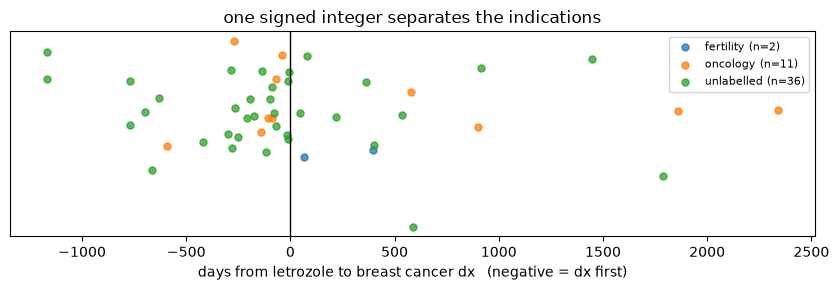

,count,mean,50%
weak_label,,,
fertility,2.0,231.0,231.0
oncology,11.0,397.0,-69.0
unlabelled,36.0,-70.0,-107.0


In [10]:
gaps = eo.signed_gap(events, 'letrozole', 'breast_cancer')
gaps = gaps.merge(weak, on='person_id', how='left')
gaps['weak_label'] = gaps['weak_label'].fillna('unlabelled')

plt.figure(figsize=(8.5, 3))
for name, g in gaps.groupby('weak_label'):
    plt.scatter(g.days_a_to_b, np.random.normal(0, .05, len(g)),
                s=26, alpha=.75, label=f"{name} (n={len(g)})")
plt.axvline(0, c='k', lw=1); plt.yticks([])
plt.xlabel('days from letrozole to breast cancer dx   (negative = dx first)')
plt.legend(fontsize=8); plt.title('one signed integer separates the indications')
plt.tight_layout(); plt.show()

display(gaps.groupby('weak_label').days_a_to_b
            .describe()[['count', 'mean', '50%']].round(0))

**One signed integer.** Worth remembering the next time the conversation turns to four weeks
of GPU pretraining.

Two cautions on real data. This feature is only meaningful where lookback covers the earlier
event — otherwise you are measuring enrolment, not biology. And for patients with no cancer
diagnosis at all the feature is NULL, which is not the same as zero; carry an explicit
`no_dx_in_lookback` flag rather than imputing.

## 5 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is close to the UI
sketch from the review, but derived from observed transitions rather than a model's guess
about the next event.

5238 letrozole patients
21 nodes, 139 edges


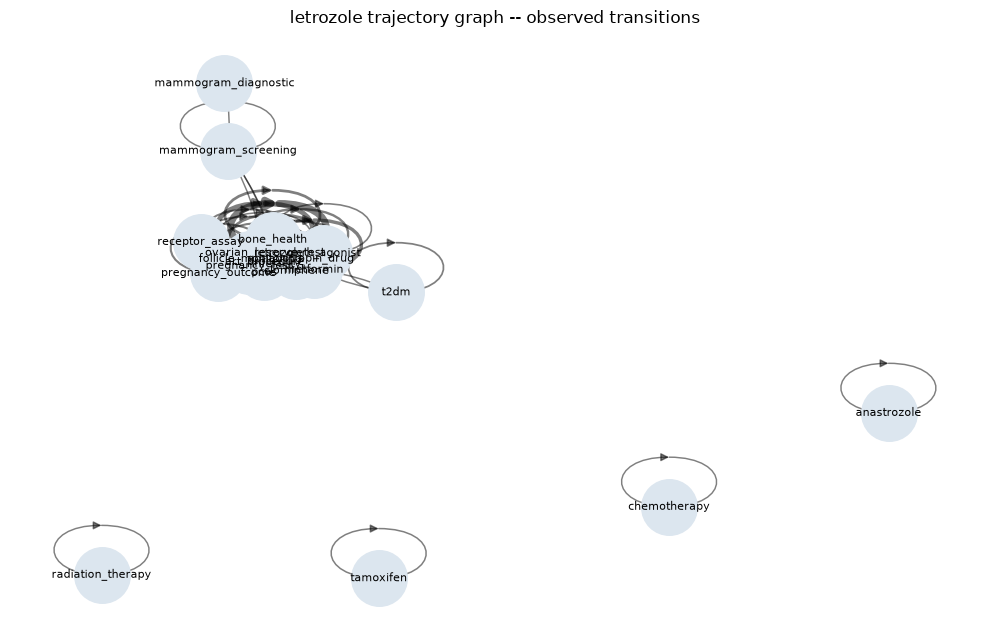

In [11]:
import networkx as nx

# every curated codeset tag (codesets.yaml via eo); the raw per-product codes would swamp the graph
FOCUS = set(eo.CODESETS)

db_lz_g = [[c for c in seqs[p] if c in FOCUS] for p in pids if 'letrozole' in seqs[p]]
print(f"{len(db_lz_g)} letrozole patients")

cnt = collections.Counter()
for s in db_lz_g:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_lz_g))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

plt.figure(figsize=(10, 6.5))
pos = nx.spring_layout(G, seed=3, k=1.1)
w   = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_nodes(G, pos, node_size=1600, node_color='#DCE6EF')
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, width=1 + 4 * w / w.max(), alpha=.5,
                       arrowsize=12, connectionstyle='arc3,rad=0.08')
plt.title('letrozole trajectory graph -- observed transitions')
plt.axis('off'); plt.tight_layout(); plt.show()


Read the arms against the NMF components: a fertility-treatment arm (clomiphene,
gonadotropins, ART), a pregnancy arm (pregnancy test, pregnancy outcome), and a much thinner
oncology arm (receptor assay, biopsy, chemotherapy, mastectomy). Whichever dominates numerically
is the answer — let the graph say which, rather than assuming.

